# Rol 2 - Traductor: s?ntesis y fitness

Referencia real: piano La4, 1 s, University of Iowa (ver `data/rol2_referencia.md`).
Este notebook contiene ?nicamente los experimentos del rol 2. La codificaci?n
logar?tmica de Nico (`src/rol1_codificacion.py`) y el AG de Naza (`src/rol4_ag.py`)
ya est?n integrados. Se ejecut? con esos m?dulos reales; la primera celda imprime
sus nombres para comprobarlo. Ejecutar desde la ra?z del repositorio o desde
`notebooks/`, con las dependencias del README.


In [1]:
from pathlib import Path
import sys, csv, time
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio, display
from importlib import import_module

ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import rol2_fitness as r2
rol1 = r2.rol1
try:
    rol4 = import_module('src.rol4_ag')
except ModuleNotFoundError as exc:
    if exc.name != 'src.rol4_ag':
        raise
    from src import _provisional as rol4
print('Codificación:', rol1.__name__, '| AG:', rol4.__name__)
print('Referencia:', r2.RUTA_REFERENCIA.name, r2.NOTA_REFERENCIA, r2.DURACION_REFERENCIA, 's')
for carpeta in ['graficos', 'tablas', 'audios']:
    (ROOT / 'results' / carpeta).mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(2026)
individuos = rng.random((100, len(rol1.GENES)))


Codificación: src.rol1_codificacion | AG: src.rol4_ag
Referencia: referencia.wav 69 1.0 s


## Dos métricas y costo

STFT: ventana Hann de 1024 muestras, salto 256, dB relativos al máximo y piso -80 dB.
El fitness es `1 - MAE/80`, usando la unión de bandas que alcanzan -60 dB en
cualquiera de los audios. Así se penalizan armónicos ausentes y extra sin premiar
miles de celdas silenciosas. Se retienen todos los tiempos para evaluar la envolvente.
El silencio obtiene cero explícitamente.

Croma: similitud coseno entre matrices de potencia agrupada en 12 clases de nota.
Agrupa octavas y pierde parte de la información del timbre: sirve como contraste.


In [2]:
mediciones = []
for nombre, fn in [('STFT', r2.fitness), ('Croma', r2.fitness_croma)]:
    fn(individuos[0])  # calentamiento fuera del cronómetro
    inicio = time.perf_counter()
    valores = np.array([fn(x) for x in individuos])
    ms = (time.perf_counter() - inicio) * 1000 / len(individuos)
    mediciones.append([nombre, ms, valores.min(), valores.mean(), valores.max()])
    print(f'{nombre}: {ms:.3f} ms/evaluación; aleatorios min/media/max = '
          f'{valores.min():.4f}/{valores.mean():.4f}/{valores.max():.4f}')
with (ROOT / 'results/tablas/rol2_tiempos.csv').open('w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['metrica','ms_por_evaluacion','min','media','max'])
    writer.writerows(mediciones)


STFT: 5.643 ms/evaluación; aleatorios min/media/max = 0.7261/0.7984/0.8705


Croma: 5.878 ms/evaluación; aleatorios min/media/max = 0.1109/0.4942/0.9051


## Validación con referencia sintética conocida

Una grabación real no tiene un cromosoma exacto. Para verificar el máximo matemático,
se sintetiza un gen conocido y se compara consigo mismo. Las pruebas automáticas
comprueban además ambas funciones públicas sustituyendo temporalmente sus referencias.


In [3]:
gen = {**{f'amp_h{h}': 1/h for h in range(1, 9)},
       'ataque': .01, 'decaimiento': .2, 'sostenido': .3,
       'liberacion': .1, 'vib_frec': 0., 'vib_prof': 0.}
x = rol1.codificar(gen)
y = r2.sintetizar_instrumento([69], [1.], rol1.decodificar(x))
mag = r2._magnitud(y)
db, croma = r2._a_db(mag), r2._croma(mag)
assert np.isclose(r2._similitud_db(db, db), 1)
assert np.isclose(np.sum(croma*croma), 1)
print('Referencia sintética contra sí misma: STFT = 1, croma = 1')


Referencia sintética contra sí misma: STFT = 1, croma = 1


## Comparación de ganadores del AG

Misma población inicial por semilla y mismo presupuesto para ambas métricas:
20 individuos, 20 generaciones, elitismo 2, operadores predeterminados del grupo.
Se evalúa cada ganador con ambas métricas; las escalas no se comparan directamente.
Es una comparación pequeña del rol 2, no el estudio de configuraciones del rol 4.


In [4]:
config = {'poblacion': 20, 'n_genes': len(rol1.GENES), 'generaciones': 20, 'elitismo': 2}
corridas = {}
filas = []
for seed in [0, 1, 2]:
    for nombre, fn in [('STFT', r2.fitness), ('Croma', r2.fitness_croma)]:
        res = rol4.ejecutar_ag(config, fn, seed)
        corridas[(seed, nombre)] = res
        fila = [seed, nombre, r2.fitness(res['mejor']), r2.fitness_croma(res['mejor'])]
        filas.append(fila)
        print(f'Semilla {seed}, optimiza {nombre}: STFT={fila[2]:.4f}, croma={fila[3]:.4f}')
    print('¿Mismo cromosoma ganador?', np.allclose(corridas[(seed, 'STFT')]['mejor'],
                                                 corridas[(seed, 'Croma')]['mejor']))
with (ROOT / 'results/tablas/rol2_comparacion_metricas.csv').open('w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['semilla','objetivo','fitness_stft','fitness_croma'])
    writer.writerows(filas)


Semilla 0, optimiza STFT: STFT=0.8962, croma=0.6825


Semilla 0, optimiza Croma: STFT=0.8701, croma=0.9764
¿Mismo cromosoma ganador? False


Semilla 1, optimiza STFT: STFT=0.8911, croma=0.6030


Semilla 1, optimiza Croma: STFT=0.8444, croma=0.9783
¿Mismo cromosoma ganador? False


Semilla 2, optimiza STFT: STFT=0.8933, croma=0.1837


Semilla 2, optimiza Croma: STFT=0.8704, croma=0.9779
¿Mismo cromosoma ganador? False


## Superficie de fitness: variar un gen

Una superficie de fitness asigna una puntuación a cada cromosoma. Esta curva es un
corte: varía el ataque y deja los otros trece genes fijos en el mejor individuo de
la primera corrida STFT. Una superficie relativamente suave permite conservar
mejoras mediante mutaciones pequeñas; picos aislados y mesetas dificultan la búsqueda.
No se exige derivabilidad para un AG. El redondeo a muestras y el umbral de bandas
pueden introducir pequeñas discontinuidades, que hay que reconocer al interpretar la curva.


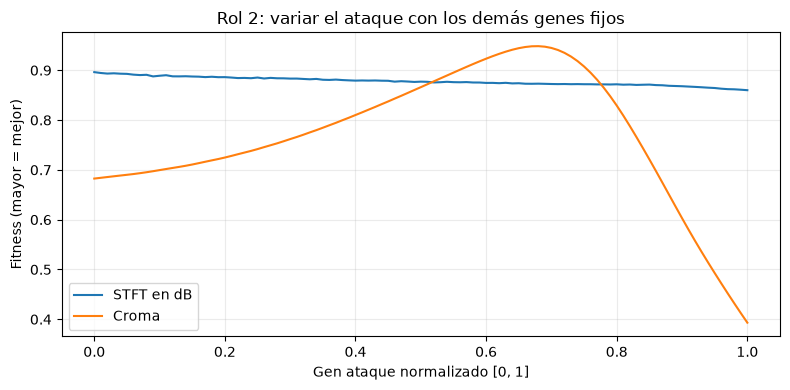

In [5]:
base = corridas[(0, 'STFT')]['mejor'].copy()
indice = [g[0] for g in rol1.GENES].index('ataque')
valores = np.linspace(0, 1, 101)
puntos = []
for valor in valores:
    prueba = base.copy()
    prueba[indice] = valor
    puntos.append([valor, r2.fitness(prueba), r2.fitness_croma(prueba)])
puntos = np.asarray(puntos)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(valores, puntos[:, 1], label='STFT en dB')
ax.plot(valores, puntos[:, 2], label='Croma')
ax.set(xlabel='Gen ataque normalizado [0, 1]', ylabel='Fitness (mayor = mejor)',
       title='Rol 2: variar el ataque con los demás genes fijos')
ax.legend(); ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(ROOT / 'results/graficos/rol2_superficie_fitness.png', dpi=150)
plt.show()
np.savetxt(ROOT / 'results/tablas/rol2_superficie_fitness.csv', puntos,
           delimiter=',', header='ataque_normalizado,fitness_stft,fitness_croma', comments='')


## Audio comparativo (misma nota La4)

Se compara la misma nota de un segundo, no se presenta la referencia real como
si fuera una melodía sintetizada. Los WAV se guardan con prefijo `rol2_`.


In [6]:
audios = {
    'referencia': r2.REFERENCIA,
    'gen0': r2.sintetizar_instrumento([69], [1.], rol1.decodificar(corridas[(0, 'STFT')]['mejor_gen0'])),
    'mejor_stft': r2.sintetizar_instrumento([69], [1.], rol1.decodificar(base)),
    'mejor_croma': r2.sintetizar_instrumento([69], [1.], rol1.decodificar(corridas[(0, 'Croma')]['mejor'])),
}
for nombre, audio in audios.items():
    sf.write(ROOT / f'results/audios/rol2_{nombre}.wav', audio, r2.SR, subtype='PCM_16')
    print(nombre)
    display(Audio(audio, rate=r2.SR))


referencia


gen0


mejor_stft


mejor_croma


## Recomendación al Rol 4 y material para «Evaluación»

Usar STFT como objetivo principal porque conserva las diferencias entre armónicos.
Usar croma como control complementario: un valor alto no garantiza un piano convincente.
Escuchar los cuatro audios y consultar la tabla de evaluación cruzada antes de elegir.
Ocho armónicos con una envolvente común no reproducen exactamente el martillo,
la inarmonicidad ni las distintas tasas de decaimiento del piano real.

**Por qué no MSE de onda cruda:** dos senos idénticos desplazados medio período
pueden dar gran error cuadrático pese a tener el mismo timbre y tono. La magnitud
STFT reduce esa dependencia de fase, manteniendo información de frecuencia y tiempo.

**Guion de diapositiva «Evaluación»:** cromosoma → decodificación → 8 armónicos +
ADSR + vibrato → STFT; comparar La4 con piano real; mayor fitness = menor error;
mostrar curva del ataque, tabla de tiempos y escuchar referencia/Gen 0/mejor STFT.

Repetir las corridas al integrar los roles 1 y 4; los resultados provisionales no
constituyen la evaluación final del grupo.
